Input: `HABs_ScrippsPier_v3.xlsx`.
Output: `outputs/step2_prepared.joblib` (feature sets A/B/C, train/validation/

In [ ]:
# Working folder: holds HABs_ScrippsPier_v3.xlsx and the outputs/ folder shared by all steps.
# In Colab the folder is on Google Drive, so every step notebook can read what the previous step saved.
import os
WORK_FOLDER = "/content/drive/MyDrive/BIF633_Progress2"
try:
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs(WORK_FOLDER, exist_ok=True)
    os.chdir(WORK_FOLDER)
except ImportError:
    pass  # not running in Colab: use the current folder
os.makedirs("outputs", exist_ok=True)
print("Working folder:", os.getcwd())

In [ ]:
# SETUP CELL: Run this before Step 4

import pandas as pd
import numpy as np
from pathlib import Path

expected_filename = "HABs_ScrippsPier_v3.xlsx"
file_path = Path(expected_filename)

# Upload the dataset if it is not available in Colab
if not file_path.exists():
    from google.colab import files

    print(f"Please upload: {expected_filename}")
    uploaded = files.upload()

    excel_files = [
        filename
        for filename in uploaded
        if filename.lower().endswith(".xlsx")
    ]

    if expected_filename in uploaded:
        file_path = Path(expected_filename)

    elif len(excel_files) == 1:
        file_path = Path(excel_files[0])

    else:
        raise FileNotFoundError(
            "Please upload exactly one Excel dataset."
        )

# Read the Excel file
df_raw = pd.read_excel(
    file_path,
    sheet_name="Sheet1"
)

# Remove the first row containing measurement units
df = (
    df_raw
    .iloc[1:]
    .copy()
    .reset_index(drop=True)
)

# Convert time
df["time"] = pd.to_datetime(
    df["time"],
    errors="coerce",
    utc=True
)

# Convert required columns to numeric
numeric_columns = [
    "Temp",
    "Chl1",
    "Chl2",
    "Avg_Chloro",
    "Phaeo1",
    "Phaeo2",
    "Avg_Phaeo",
    "Phosphate",
    "Silicate",
    "Nitrite",
    "Ammonium",
    "Nitrate",
    "Total_Phytoplankton"
]

df[numeric_columns] = (
    df[numeric_columns]
    .apply(pd.to_numeric, errors="coerce")
)

# Sort chronologically
df = (
    df
    .sort_values("time")
    .reset_index(drop=True)
)

print("Dataset file:", file_path)
print("Dataset shape:", df.shape)
print("Start date:", df["time"].min())
print("End date:", df["time"].max())
print("Duplicate timestamps:", df["time"].duplicated().sum())

Dataset file: HABs_ScrippsPier_v3.xlsx
Dataset shape: (522, 21)
Start date: 2016-08-01 16:21:00+00:00
End date: 2026-07-27 18:16:00+00:00
Duplicate timestamps: 0


In [ ]:
# Step 4.1 - Create a clean working table
# from the Step 3 dataframe

required_columns = [
    "time",
    "Avg_Chloro",
    "Temp",
    "Phosphate",
    "Silicate",
    "Nitrite",
    "Ammonium",
    "Nitrate"
]

missing_required = [
    column
    for column in required_columns
    if column not in df.columns
]

if missing_required:
    raise KeyError(
        f"Required columns are missing: {missing_required}"
    )

step4_df = df[required_columns].copy()

step4_df["time"] = pd.to_datetime(
    step4_df["time"],
    errors="coerce",
    utc=True
)

numeric_step4 = [
    column
    for column in required_columns
    if column != "time"
]

step4_df[numeric_step4] = (
    step4_df[numeric_step4]
    .apply(pd.to_numeric, errors="coerce")
)

step4_df = (
    step4_df
    .dropna(subset=["time", "Avg_Chloro"])
    .sort_values("time")
    .reset_index(drop=True)
)

print(
    "Observations before feature engineering:",
    len(step4_df)
)

print(
    "Start date:",
    step4_df["time"].min()
)

print(
    "End date:",
    step4_df["time"].max()
)

print(
    "Duplicate timestamps:",
    step4_df["time"].duplicated().sum()
)


Observations before feature engineering: 522
Start date: 2016-08-01 16:21:00+00:00
End date: 2026-07-27 18:16:00+00:00
Duplicate timestamps: 0


In [ ]:
#Step4
#Prepare the working dataset

required_columns = [
    "time",
    "Avg_Chloro",
    "Temp",
    "Phosphate",
    "Silicate",
    "Nitrite",
    "Ammonium",
    "Nitrate"
]

# Check whether all required columns exist
missing_required = [
    column
    for column in required_columns
    if column not in df.columns
]

if missing_required:
    raise KeyError(
        f"Required columns are missing: {missing_required}"
    )

# Create a separate dataframe for feature engineering
step4_df = df[required_columns].copy()

# Ensure that time is datetime
step4_df["time"] = pd.to_datetime(
    step4_df["time"],
    errors="coerce",
    utc=True
)

# Ensure that measurements are numeric
numeric_step4 = [
    column
    for column in required_columns
    if column != "time"
]

step4_df[numeric_step4] = (
    step4_df[numeric_step4]
    .apply(
        pd.to_numeric,
        errors="coerce"
    )
)

# Remove rows without time or target
# Sort the observations chronologically
step4_df = (
    step4_df
    .dropna(
        subset=[
            "time",
            "Avg_Chloro"
        ]
    )
    .sort_values("time")
    .reset_index(drop=True)
)

print(
    "Observations before feature engineering:",
    len(step4_df)
)

print(
    "Start date:",
    step4_df["time"].min()
)

print(
    "End date:",
    step4_df["time"].max()
)

print(
    "Duplicate timestamps:",
    step4_df["time"]
    .duplicated()
    .sum()
)

Observations before feature engineering: 522
Start date: 2016-08-01 16:21:00+00:00
End date: 2026-07-27 18:16:00+00:00
Duplicate timestamps: 0


In [ ]:
# Step 4.2 - Create the next-sampling-time target
# and cyclical month features

# Target: chlorophyll-a at the next sampling time
step4_df["target_next"] = (
    step4_df["Avg_Chloro"]
    .shift(-1)
)

# Alternative log-transformed target
# This is an outcome, not a predictor
step4_df["target_next_log"] = np.log1p(
    step4_df["target_next"]
)

# Extract calendar month
step4_df["month"] = (
    step4_df["time"]
    .dt.month
)

# Encode month as a cyclical variable
step4_df["month_sin"] = np.sin(
    2
    * np.pi
    * step4_df["month"]
    / 12
)

step4_df["month_cos"] = np.cos(
    2
    * np.pi
    * step4_df["month"]
    / 12
)

print(
    "Prediction task:"
    " predictors at time t predict"
    " chlorophyll-a at time t+1"
)

display(
    step4_df[
        [
            "time",
            "Avg_Chloro",
            "target_next",
            "target_next_log",
            "month",
            "month_sin",
            "month_cos"
        ]
    ].head(10)
)


Prediction task: predictors at time t predict chlorophyll-a at time t+1


,time,Avg_Chloro,target_next,target_next_log,month,month_sin,month_cos
0,2016-08-01 16:21:00+00:00,5.12,7.07,2.088153,8,-0.866025,-5.000000e-01
1,2016-08-08 16:15:00+00:00,7.07,4.39,1.684545,8,-0.866025,-5.000000e-01
2,2016-08-15 17:09:00+00:00,4.39,2.08,1.124930,8,-0.866025,-5.000000e-01
3,2016-08-22 15:44:00+00:00,2.08,2.27,1.184790,8,-0.866025,-5.000000e-01
4,2016-08-29 16:05:00+00:00,2.27,1.84,1.043804,8,-0.866025,-5.000000e-01
5,2016-09-06 15:50:00+00:00,1.84,1.55,0.936093,9,-1.000000,-1.836970e-16
6,2016-09-12 16:19:00+00:00,1.55,2.80,1.335001,9,-1.000000,-1.836970e-16
7,2016-09-19 15:50:00+00:00,2.80,1.31,0.837248,9,-1.000000,-1.836970e-16
8,2016-09-26 16:05:00+00:00,1.31,1.88,1.057790,9,-1.000000,-1.836970e-16
9,2016-10-03 16:05:00+00:00,1.88,1.92,1.071584,10,-0.866025,5.000000e-01


In [ ]:
# Step 4.3 - Create historical chlorophyll-a features

# Chlorophyll-a currently known at time t
step4_df["Chloro_current"] = (
    step4_df["Avg_Chloro"]
)

# Create lag features from t-1 to t-5
for lag in range(1, 6):

    step4_df[f"Chloro_lag{lag}"] = (
        step4_df["Avg_Chloro"]
        .shift(lag)
    )

# Mean of the four most recent known observations:
# t, t-1, t-2 and t-3
step4_df["Chloro_roll4"] = (
    step4_df["Avg_Chloro"]
    .rolling(
        window=4,
        min_periods=4
    )
    .mean()
)

historical_features = [
    "Chloro_current",
    "Chloro_lag1",
    "Chloro_lag2",
    "Chloro_lag3",
    "Chloro_lag4",
    "Chloro_lag5",
    "Chloro_roll4"
]

display(
    step4_df[
        [
            "time",
            *historical_features,
            "target_next"
        ]
    ].head(10)
)


,time,Chloro_current,Chloro_lag1,Chloro_lag2,Chloro_lag3,Chloro_lag4,Chloro_lag5,Chloro_roll4,target_next
0,2016-08-01 16:21:00+00:00,5.12,NaN,NaN,NaN,NaN,NaN,NaN,7.07
1,2016-08-08 16:15:00+00:00,7.07,5.12,NaN,NaN,NaN,NaN,NaN,4.39
2,2016-08-15 17:09:00+00:00,4.39,7.07,5.12,NaN,NaN,NaN,NaN,2.08
3,2016-08-22 15:44:00+00:00,2.08,4.39,7.07,5.12,NaN,NaN,4.6650,2.27
4,2016-08-29 16:05:00+00:00,2.27,2.08,4.39,7.07,5.12,NaN,3.9525,1.84
5,2016-09-06 15:50:00+00:00,1.84,2.27,2.08,4.39,7.07,5.12,2.6450,1.55
6,2016-09-12 16:19:00+00:00,1.55,1.84,2.27,2.08,4.39,7.07,1.9350,2.80
7,2016-09-19 15:50:00+00:00,2.80,1.55,1.84,2.27,2.08,4.39,2.1150,1.31
8,2016-09-26 16:05:00+00:00,1.31,2.80,1.55,1.84,2.27,2.08,1.8750,1.88
9,2016-10-03 16:05:00+00:00,1.88,1.31,2.80,1.55,1.84,2.27,1.8850,1.92


In [ ]:
# Step 4.4 - Preserve nutrient zeros
# and create optional detection indicators

# Keep missing Nitrite as NaN
# 0 = recorded zero
# 1 = concentration greater than zero
step4_df["Nitrite_detected"] = np.where(
    step4_df["Nitrite"].isna(),
    np.nan,
    (
        step4_df["Nitrite"] > 0
    ).astype(float)
)

# Keep missing Nitrate as NaN
# 0 = recorded zero
# 1 = concentration greater than zero
step4_df["Nitrate_detected"] = np.where(
    step4_df["Nitrate"].isna(),
    np.nan,
    (
        step4_df["Nitrate"] > 0
    ).astype(float)
)

print(
    "Nitrite recorded zeros:",
    (
        step4_df["Nitrite"] == 0
    ).sum()
)

print(
    "Nitrite missing values:",
    step4_df["Nitrite"]
    .isna()
    .sum()
)

print(
    "Nitrate recorded zeros:",
    (
        step4_df["Nitrate"] == 0
    ).sum()
)

print(
    "Nitrate missing values:",
    step4_df["Nitrate"]
    .isna()
    .sum()
)

display(
    step4_df[
        [
            "Nitrite",
            "Nitrite_detected",
            "Nitrate",
            "Nitrate_detected"
        ]
    ].head(15)
)


Nitrite recorded zeros: 499
Nitrite missing values: 2
Nitrate recorded zeros: 232
Nitrate missing values: 2


,Nitrite,Nitrite_detected,Nitrate,Nitrate_detected
0,0.0,0.0,0.53,1.0
1,0.0,0.0,0.27,1.0
2,0.0,0.0,0.30,1.0
3,0.0,0.0,0.45,1.0
4,0.0,0.0,0.29,1.0
5,0.0,0.0,0.00,0.0
6,0.0,0.0,0.35,1.0
7,0.0,0.0,0.28,1.0
8,0.0,0.0,0.29,1.0
9,0.0,0.0,0.29,1.0


In [ ]:
# Step 4.5 - Define candidate feature sets

# Model A: environmental predictors
environmental_features = [
    "Temp",
    "Phosphate",
    "Silicate",
    "Nitrite",
    "Ammonium",
    "Nitrate"
]

# Seasonal features derived from the calendar month
seasonal_features = [
    "month_sin",
    "month_cos"
]

# Historical features derived from chlorophyll-a
historical_features = [
    "Chloro_current",
    "Chloro_lag1",
    "Chloro_lag2",
    "Chloro_lag3",
    "Chloro_lag4",
    "Chloro_lag5",
    "Chloro_roll4"
]

# Optional features for nutrient detection
candidate_detection_features = [
    "Nitrite_detected",
    "Nitrate_detected"
]

# Model A: environmental variables only
features_A = (
    environmental_features.copy()
)

# Model B: environmental and seasonal variables
features_B = (
    environmental_features
    + seasonal_features
)

# Model C: environmental, seasonal
# and historical variables
features_C = (
    environmental_features
    + seasonal_features
    + historical_features
)

print(
    "Model A:",
    len(features_A),
    "features"
)

print(features_A)

print(
    "\nModel B:",
    len(features_B),
    "features"
)

print(features_B)

print(
    "\nModel C:",
    len(features_C),
    "features"
)

print(features_C)

print(
    "\nOptional detection features:"
)

print(
    candidate_detection_features
)

Model A: 6 features
['Temp', 'Phosphate', 'Silicate', 'Nitrite', 'Ammonium', 'Nitrate']

Model B: 8 features
['Temp', 'Phosphate', 'Silicate', 'Nitrite', 'Ammonium', 'Nitrate', 'month_sin', 'month_cos']

Model C: 15 features
['Temp', 'Phosphate', 'Silicate', 'Nitrite', 'Ammonium', 'Nitrate', 'month_sin', 'month_cos', 'Chloro_current', 'Chloro_lag1', 'Chloro_lag2', 'Chloro_lag3', 'Chloro_lag4', 'Chloro_lag5', 'Chloro_roll4']

Optional detection features:
['Nitrite_detected', 'Nitrate_detected']


In [ ]:
# Step 4.6 - Create the final
# feature-engineered modeling dataset

# Remove rows that do not have:
# 1. the next-sampling-time target
# 2. complete chlorophyll-a history through lag 5
#
# Environmental missing values remain in the dataset.
# They will be imputed after chronological splitting.

model_df = (
    step4_df
    .dropna(
        subset=[
            "target_next",
            *historical_features
        ]
    )
    .copy()
)

# Reset index after filtering
model_df = (
    model_df
    .reset_index(drop=True)
)

# Check chronological order
assert (
    model_df["time"]
    .is_monotonic_increasing
)

# Check target completeness
assert (
    model_df["target_next"]
    .notna()
    .all()
)

# Check historical feature completeness
assert (
    model_df[historical_features]
    .notna()
    .all()
    .all()
)

# Check the range of cyclical month features
assert (
    model_df["month_sin"]
    .between(-1, 1)
    .all()
)

assert (
    model_df["month_cos"]
    .between(-1, 1)
    .all()
)

print(
    "Rows before lag and target filtering:",
    len(step4_df)
)

print(
    "Rows available for modeling:",
    len(model_df)
)

print(
    "Rows removed:",
    len(step4_df)
    - len(model_df)
)

print(
    "Modeling period:",
    model_df["time"].min(),
    "to",
    model_df["time"].max()
)

print(
    "Missing environmental values remain"
    " for train-only imputation."
)

display(
    model_df[
        [
            "time",
            *features_C,
            "target_next",
            "target_next_log"
        ]
    ].head()
)

Rows before lag and target filtering: 522
Rows available for modeling: 516
Rows removed: 6
Modeling period: 2016-09-06 15:50:00+00:00 to 2026-07-20 18:17:00+00:00
Missing environmental values remain for train-only imputation.


,time,Temp,Phosphate,Silicate,Nitrite,Ammonium,Nitrate,month_sin,month_cos,Chloro_current,Chloro_lag1,Chloro_lag2,Chloro_lag3,Chloro_lag4,Chloro_lag5,Chloro_roll4,target_next,target_next_log
0,2016-09-06 15:50:00+00:00,21.2,0.23,2.9,0.0,0.46,0.00,-1.000000,-1.836970e-16,1.84,2.27,2.08,4.39,7.07,5.12,2.645,1.55,0.936093
1,2016-09-12 16:19:00+00:00,20.3,0.27,3.0,0.0,0.40,0.35,-1.000000,-1.836970e-16,1.55,1.84,2.27,2.08,4.39,7.07,1.935,2.80,1.335001
2,2016-09-19 15:50:00+00:00,19.0,0.29,3.8,0.0,0.37,0.28,-1.000000,-1.836970e-16,2.80,1.55,1.84,2.27,2.08,4.39,2.115,1.31,0.837248
3,2016-09-26 16:05:00+00:00,18.0,0.31,3.6,0.0,0.67,0.29,-1.000000,-1.836970e-16,1.31,2.80,1.55,1.84,2.27,2.08,1.875,1.88,1.057790
4,2016-10-03 16:05:00+00:00,18.8,0.35,3.5,0.0,0.83,0.29,-0.866025,5.000000e-01,1.88,1.31,2.80,1.55,1.84,2.27,1.885,1.92,1.071584


In [ ]:
print(
    "model_df shape:",
    model_df.shape
)

print(
    "Number of Model A features:",
    len(features_A)
)

print(
    "Number of Model B features:",
    len(features_B)
)

print(
    "Number of Model C features:",
    len(features_C)
)

print(
    "Missing target:",
    model_df["target_next"]
    .isna()
    .sum()
)

print(
    "Step 4 completed successfully."
)

model_df shape: (516, 22)
Number of Model A features: 6
Number of Model B features: 8
Number of Model C features: 15
Missing target: 0
Step 4 completed successfully.


In [ ]:
model_df
features_A
features_B
features_C

['Temp',
 'Phosphate',
 'Silicate',
 'Nitrite',
 'Ammonium',
 'Nitrate',
 'month_sin',
 'month_cos',
 'Chloro_current',
 'Chloro_lag1',
 'Chloro_lag2',
 'Chloro_lag3',
 'Chloro_lag4',
 'Chloro_lag5',
 'Chloro_roll4']

In [ ]:
#Step 5
#Training 70% Validation 15% Test 15 %

# Step 5.1 - Verify chronological order

# Create a separate copy for splitting
split_df = (
    model_df
    .copy()
    .sort_values("time")
    .reset_index(drop=True)
)

# Check the number of observations
n_total = len(split_df)

print(
    "Total modeling observations:",
    n_total
)

print(
    "Start date:",
    split_df["time"].min()
)

print(
    "End date:",
    split_df["time"].max()
)

print(
    "Chronologically ordered:",
    split_df["time"].is_monotonic_increasing
)

print(
    "Duplicate timestamps:",
    split_df["time"]
    .duplicated()
    .sum()
)

Total modeling observations: 516
Start date: 2016-09-06 15:50:00+00:00
End date: 2026-07-20 18:17:00+00:00
Chronologically ordered: True
Duplicate timestamps: 0


In [ ]:
# Step 5.2 - Calculate chronological split positions

train_ratio = 0.70
validation_ratio = 0.15
test_ratio = 0.15

# Check that the proportions sum to 1
assert np.isclose(
    train_ratio
    + validation_ratio
    + test_ratio,
    1.0
)

n_train = int(
    n_total * train_ratio
)

n_validation = int(
    n_total * validation_ratio
)

# Assign the remaining observations to Test
n_test = (
    n_total
    - n_train
    - n_validation
)

train_end = n_train

validation_end = (
    n_train
    + n_validation
)

print(
    "Training observations:",
    n_train
)

print(
    "Validation observations:",
    n_validation
)

print(
    "Test observations:",
    n_test
)

print(
    "Total:",
    n_train
    + n_validation
    + n_test
)

Training observations: 361
Validation observations: 77
Test observations: 78
Total: 516


In [ ]:
# Step 5.3 - Perform the chronological split

train_df = (
    split_df
    .iloc[:train_end]
    .copy()
)

validation_df = (
    split_df
    .iloc[
        train_end:validation_end
    ]
    .copy()
)

test_df = (
    split_df
    .iloc[validation_end:]
    .copy()
)

# Reset indices within each partition
train_df = train_df.reset_index(
    drop=True
)

validation_df = validation_df.reset_index(
    drop=True
)

test_df = test_df.reset_index(
    drop=True
)

print(
    "Train shape:",
    train_df.shape
)

print(
    "Validation shape:",
    validation_df.shape
)

print(
    "Test shape:",
    test_df.shape
)

Train shape: (361, 22)
Validation shape: (77, 22)
Test shape: (78, 22)


In [ ]:
# Step 5.4 - Summarize each chronological partition

split_summary = pd.DataFrame(
    {
        "Dataset": [
            "Training",
            "Validation",
            "Test"
        ],

        "Observations": [
            len(train_df),
            len(validation_df),
            len(test_df)
        ],

        "Percentage": [
            len(train_df)
            / n_total
            * 100,

            len(validation_df)
            / n_total
            * 100,

            len(test_df)
            / n_total
            * 100
        ],

        "Start_date": [
            train_df["time"].min(),
            validation_df["time"].min(),
            test_df["time"].min()
        ],

        "End_date": [
            train_df["time"].max(),
            validation_df["time"].max(),
            test_df["time"].max()
        ]
    }
)

split_summary["Percentage"] = (
    split_summary["Percentage"]
    .round(2)
)

display(split_summary)

,Dataset,Observations,Percentage,Start_date,End_date
0,Training,361,69.96,2016-09-06 15:50:00+00:00,2023-07-31 19:10:00+00:00
1,Validation,77,14.92,2023-08-07 19:05:00+00:00,2025-01-21 20:35:00+00:00
2,Test,78,15.12,2025-01-27 20:13:00+00:00,2026-07-20 18:17:00+00:00


In [ ]:
# Step 5.5 - Check chronological separation

print(
    "Last Training date:",
    train_df["time"].max()
)

print(
    "First Validation date:",
    validation_df["time"].min()
)

print(
    "Last Validation date:",
    validation_df["time"].max()
)

print(
    "First Test date:",
    test_df["time"].min()
)

# Chronological boundary checks
assert (
    train_df["time"].max()
    <
    validation_df["time"].min()
)

assert (
    validation_df["time"].max()
    <
    test_df["time"].min()
)

# Check that no timestamps overlap
assert set(
    train_df["time"]
).isdisjoint(
    set(validation_df["time"])
)

assert set(
    train_df["time"]
).isdisjoint(
    set(test_df["time"])
)

assert set(
    validation_df["time"]
).isdisjoint(
    set(test_df["time"])
)

# Check that all rows are retained
assert (
    len(train_df)
    + len(validation_df)
    + len(test_df)
    ==
    len(split_df)
)

print(
    "Chronological split checks passed."
)

Last Training date: 2023-07-31 19:10:00+00:00
First Validation date: 2023-08-07 19:05:00+00:00
Last Validation date: 2025-01-21 20:35:00+00:00
First Test date: 2025-01-27 20:13:00+00:00
Chronological split checks passed.


In [ ]:
# Step 5.6 - Separate target variables

y_train = (
    train_df["target_next"]
    .copy()
)

y_validation = (
    validation_df["target_next"]
    .copy()
)

y_test = (
    test_df["target_next"]
    .copy()
)

# Alternative log-transformed outcomes
y_train_log = (
    train_df["target_next_log"]
    .copy()
)

y_validation_log = (
    validation_df["target_next_log"]
    .copy()
)

y_test_log = (
    test_df["target_next_log"]
    .copy()
)

print(
    "y_train:",
    y_train.shape
)

print(
    "y_validation:",
    y_validation.shape
)

print(
    "y_test:",
    y_test.shape
)

print(
    "Missing target in Training:",
    y_train.isna().sum()
)

print(
    "Missing target in Validation:",
    y_validation.isna().sum()
)

print(
    "Missing target in Test:",
    y_test.isna().sum()
)

y_train: (361,)
y_validation: (77,)
y_test: (78,)
Missing target in Training: 0
Missing target in Validation: 0
Missing target in Test: 0


In [ ]:
# Step 5.7 - Create feature matrices
# for Models A, B and C

feature_sets = {
    "Model_A": features_A,
    "Model_B": features_B,
    "Model_C": features_C
}

X_train = {}
X_validation = {}
X_test = {}

for model_name, feature_list in feature_sets.items():

    X_train[model_name] = (
        train_df[feature_list]
        .copy()
    )

    X_validation[model_name] = (
        validation_df[feature_list]
        .copy()
    )

    X_test[model_name] = (
        test_df[feature_list]
        .copy()
    )

    print(
        model_name
    )

    print(
        "  Training:",
        X_train[model_name].shape
    )

    print(
        "  Validation:",
        X_validation[model_name].shape
    )

    print(
        "  Test:",
        X_test[model_name].shape
    )

Model_A
  Training: (361, 6)
  Validation: (77, 6)
  Test: (78, 6)
Model_B
  Training: (361, 8)
  Validation: (77, 8)
  Test: (78, 8)
Model_C
  Training: (361, 15)
  Validation: (77, 15)
  Test: (78, 15)


In [ ]:
# Step 5.8 - Inspect missing values
# without performing imputation

missing_by_split = pd.DataFrame(
    {
        "Training_missing": (
            train_df[
                environmental_features
            ]
            .isna()
            .sum()
        ),

        "Validation_missing": (
            validation_df[
                environmental_features
            ]
            .isna()
            .sum()
        ),

        "Test_missing": (
            test_df[
                environmental_features
            ]
            .isna()
            .sum()
        )
    }
)

display(
    missing_by_split
)

,Training_missing,Validation_missing,Test_missing
Temp,0,0,0
Phosphate,0,0,1
Silicate,0,0,1
Nitrite,0,0,1
Ammonium,0,1,1
Nitrate,0,0,1


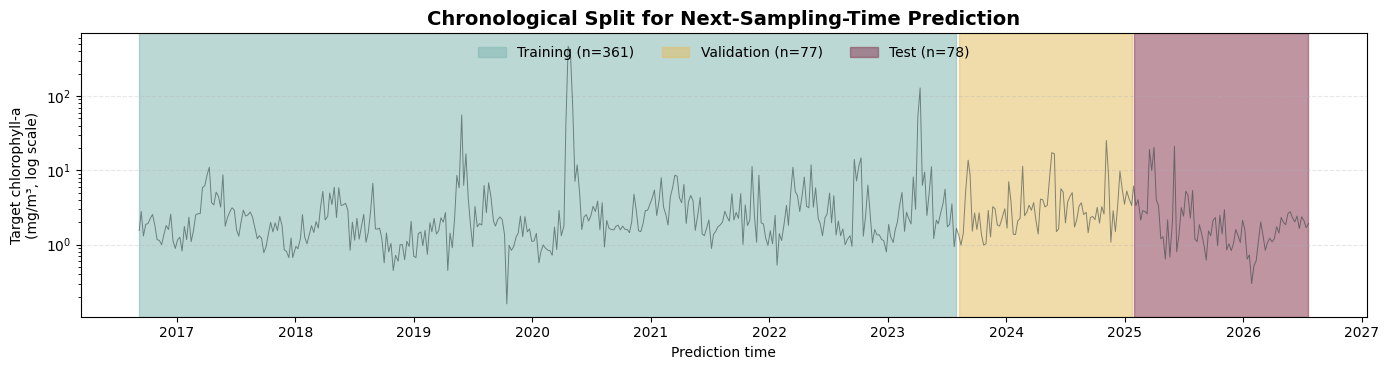

In [ ]:
# Step 5.9 - Visualize the chronological split

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, ax = plt.subplots(
    figsize=(14, 3.8)
)

ax.axvspan(
    train_df["time"].min(),
    train_df["time"].max(),
    color="#84B8B2",
    alpha=0.55,
    label=f"Training (n={len(train_df)})"
)

ax.axvspan(
    validation_df["time"].min(),
    validation_df["time"].max(),
    color="#E4BE65",
    alpha=0.55,
    label=(
        f"Validation "
        f"(n={len(validation_df)})"
    )
)

ax.axvspan(
    test_df["time"].min(),
    test_df["time"].max(),
    color="#8B3F57",
    alpha=0.55,
    label=f"Test (n={len(test_df)})"
)

# Plot the target values to show time coverage
ax.plot(
    split_df["time"],
    split_df["target_next"],
    color="#26383A",
    linewidth=0.7,
    alpha=0.55
)

ax.set_yscale("log")

ax.set_title(
    "Chronological Split for Next-Sampling-Time Prediction",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel(
    "Prediction time"
)

ax.set_ylabel(
    "Target chlorophyll-a\n(mg/m³, log scale)"
)

ax.xaxis.set_major_locator(
    mdates.YearLocator(1)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y")
)

ax.legend(
    frameon=False,
    ncol=3,
    loc="upper center"
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()
plt.show()
plt.close()

In [ ]:
train_df
validation_df
test_df

y_train
y_validation
y_test

X_train
X_validation
X_test

split_summary

,Dataset,Observations,Percentage,Start_date,End_date
0,Training,361,69.96,2016-09-06 15:50:00+00:00,2023-07-31 19:10:00+00:00
1,Validation,77,14.92,2023-08-07 19:05:00+00:00,2025-01-21 20:35:00+00:00
2,Test,78,15.12,2025-01-27 20:13:00+00:00,2026-07-20 18:17:00+00:00


In [ ]:
# ============================================================
# STEP 6.1 — SETUP FEATURE SETS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor


# Check that Step 5 has already been executed
required_dataframes = ["train_df", "validation_df", "test_df"]

missing_dataframes = [
    name for name in required_dataframes
    if name not in globals()
]

if missing_dataframes:
    raise NameError(
        "Please run Step 4 and Step 5 first. "
        f"Missing objects: {missing_dataframes}"
    )


# Target used for model training
target_column = "target_next_log"


# Feature Set A: environmental variables
feature_set_A = [
    "Temp",
    "Phosphate",
    "Silicate",
    "Nitrite",
    "Ammonium",
    "Nitrate"
]


# Feature Set B: environmental + seasonal variables
feature_set_B = feature_set_A + [
    "month_sin",
    "month_cos"
]


# Feature Set C: environmental + seasonal + temporal history
feature_set_C = feature_set_B + [
    "Chloro_current",
    "Chloro_lag1",
    "Chloro_lag2",
    "Chloro_lag3",
    "Chloro_lag4",
    "Chloro_lag5",
    "Chloro_roll4"
]


feature_sets = {
    "A_Environmental": feature_set_A,
    "B_Environmental_Seasonal": feature_set_B,
    "C_Full_Temporal": feature_set_C
}


# Check required columns
required_columns = list(
    dict.fromkeys(feature_set_C + [target_column])
)

for dataframe_name, dataframe in {
    "Training": train_df,
    "Validation": validation_df,
    "Test": test_df
}.items():

    missing_columns = [
        column for column in required_columns
        if column not in dataframe.columns
    ]

    if missing_columns:
        raise KeyError(
            f"{dataframe_name} is missing columns: {missing_columns}"
        )


print("Step 6 setup completed.")
print("Target:", target_column)

for set_name, columns in feature_sets.items():
    print(f"{set_name}: {len(columns)} predictors")

Step 6 setup completed.
Target: target_next_log
A_Environmental: 6 predictors
B_Environmental_Seasonal: 8 predictors
C_Full_Temporal: 15 predictors


In [ ]:
# ============================================================
# STEP 6.2 — MISSING-VALUE INSPECTION
# ============================================================

missing_summary = pd.DataFrame({
    "Training_missing": train_df[feature_set_C].isna().sum(),
    "Validation_missing": validation_df[feature_set_C].isna().sum(),
    "Test_missing": test_df[feature_set_C].isna().sum()
})

missing_summary["Training_missing_percent"] = (
    missing_summary["Training_missing"] / len(train_df) * 100
).round(2)

missing_summary = missing_summary.sort_values(
    by="Training_missing",
    ascending=False
)

display(missing_summary)

print("\nMissing target values:")
print("Training:", train_df[target_column].isna().sum())
print("Validation:", validation_df[target_column].isna().sum())
print("Test:", test_df[target_column].isna().sum())

,Training_missing,Validation_missing,Test_missing,Training_missing_percent
Temp,0,0,0,0.0
Phosphate,0,0,1,0.0
Silicate,0,0,1,0.0
Nitrite,0,0,1,0.0
Ammonium,0,1,1,0.0
Nitrate,0,0,1,0.0
month_sin,0,0,0,0.0
month_cos,0,0,0,0.0
Chloro_current,0,0,0,0.0
Chloro_lag1,0,0,0,0.0



Missing target values:
Training: 0
Validation: 0
Test: 0


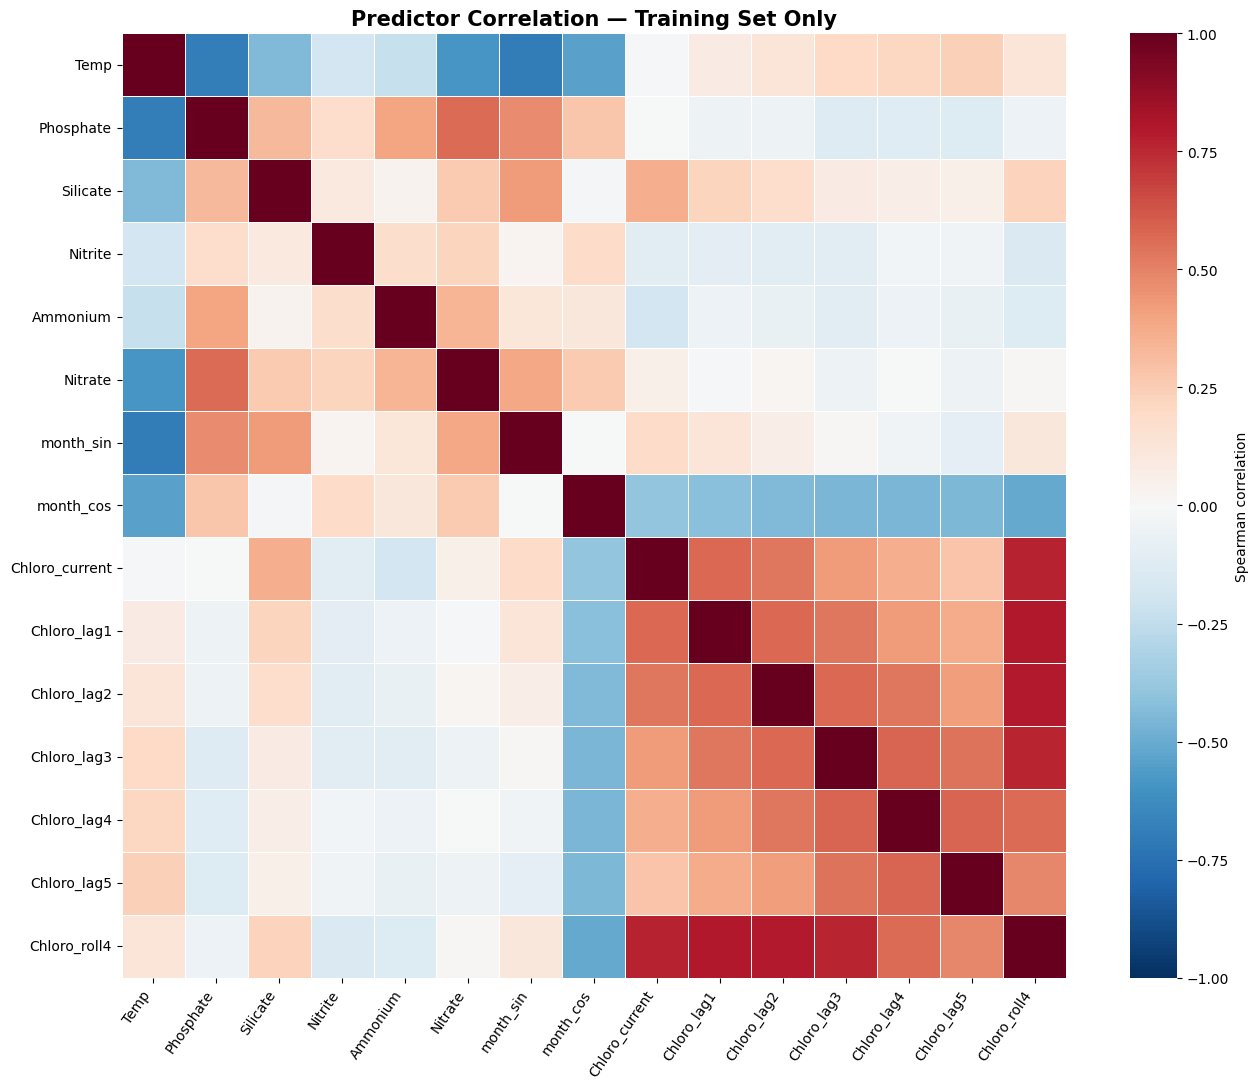

No predictor pairs have |correlation| >= 0.9.


In [ ]:
# ============================================================
# STEP 6.3 — CORRELATION CHECK: TRAINING SET ONLY
# ============================================================

correlation_threshold = 0.90

train_correlation = train_df[feature_set_C].corr(
    method="spearman"
)

plt.figure(figsize=(14, 11))

sns.heatmap(
    train_correlation,
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.4,
    cbar_kws={"label": "Spearman correlation"}
)

plt.title(
    "Predictor Correlation — Training Set Only",
    fontsize=15,
    fontweight="bold"
)

plt.xticks(rotation=55, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


# Find highly correlated predictor pairs
upper_triangle = train_correlation.abs().where(
    np.triu(
        np.ones(train_correlation.shape),
        k=1
    ).astype(bool)
)

high_correlation_pairs = []

for column in upper_triangle.columns:
    correlated_rows = upper_triangle.index[
        upper_triangle[column] >= correlation_threshold
    ]

    for row in correlated_rows:
        high_correlation_pairs.append({
            "Feature_1": row,
            "Feature_2": column,
            "Spearman_r": train_correlation.loc[row, column],
            "Absolute_r": abs(train_correlation.loc[row, column])
        })


high_correlation_table = pd.DataFrame(
    high_correlation_pairs
)

if high_correlation_table.empty:
    print(
        f"No predictor pairs have |correlation| >= "
        f"{correlation_threshold}."
    )
else:
    high_correlation_table = high_correlation_table.sort_values(
        "Absolute_r",
        ascending=False
    )

    print(
        f"Predictor pairs with |correlation| >= "
        f"{correlation_threshold}:"
    )

    display(high_correlation_table)

In [ ]:
# ============================================================
# STEP 6.4 — TRAINING-ONLY IMPUTATION FOR VIF
# ============================================================

vif_imputer = SimpleImputer(strategy="median")

X_train_C_for_vif = pd.DataFrame(
    vif_imputer.fit_transform(
        train_df[feature_set_C]
    ),
    columns=feature_set_C,
    index=train_df.index
)

print("Training matrix for VIF:", X_train_C_for_vif.shape)
print(
    "Missing values after temporary Training imputation:",
    X_train_C_for_vif.isna().sum().sum()
)

Training matrix for VIF: (361, 15)
Missing values after temporary Training imputation: 0


/tmp/ipykernel_2282/1407565882.py:24: UserWarning: The design matrix is poorly conditioned (condition number=7.86e+15). VIF calculations may be numerically unstable.
  variance_inflation_factor(
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatr

,Feature,VIF
0,Chloro_lag2,1.000800e+15
1,Chloro_lag1,1.000800e+15
2,Chloro_roll4,1.000800e+15
3,Chloro_lag3,1.000800e+15
4,Chloro_current,1.000800e+15
5,Temp,6.702390e+00
6,Chloro_lag4,4.149893e+00
7,month_sin,3.676529e+00
8,month_cos,2.650513e+00
9,Ammonium,2.228679e+00


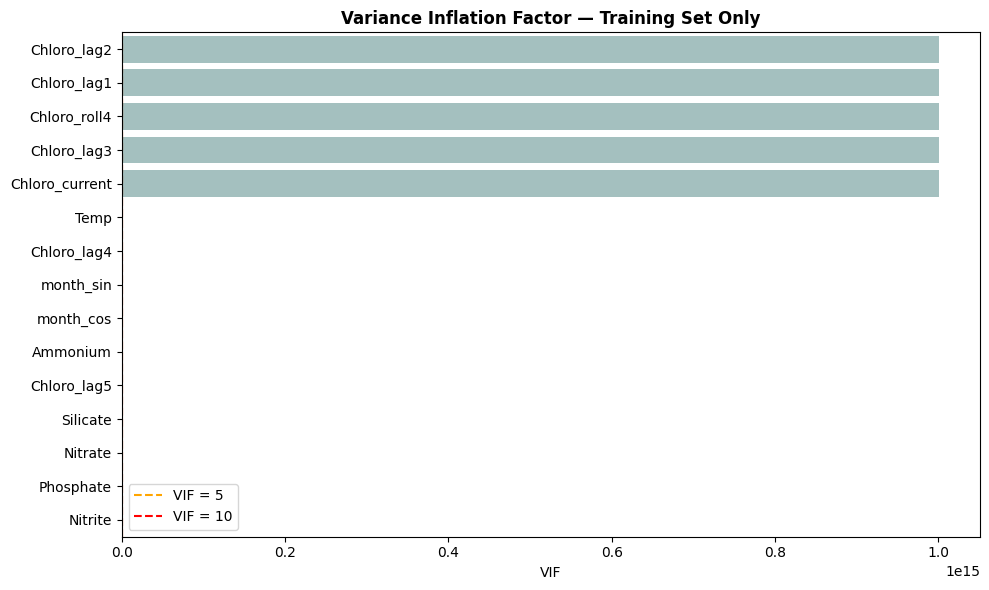

In [ ]:
# ============================================================
# STEP 6.5 — VIF CHECK: TRAINING SET ONLY
# ============================================================

def calculate_vif(dataframe):
    """
    Calculate VIF for a numeric predictor dataframe.
    The dataframe must not contain missing or infinite values.
    """

    clean_dataframe = dataframe.replace(
        [np.inf, -np.inf],
        np.nan
    )

    if clean_dataframe.isna().any().any():
        raise ValueError(
            "VIF input still contains missing or infinite values."
        )

    vif_table = pd.DataFrame({
        "Feature": clean_dataframe.columns,
        "VIF": [
            variance_inflation_factor(
                clean_dataframe.values,
                feature_index
            )
            for feature_index in range(
                clean_dataframe.shape[1]
            )
        ]
    })

    return vif_table.sort_values(
        "VIF",
        ascending=False
    ).reset_index(drop=True)


vif_before_selection = calculate_vif(
    X_train_C_for_vif
)

display(vif_before_selection)


plt.figure(figsize=(10, 6))

sns.barplot(
    data=vif_before_selection,
    x="VIF",
    y="Feature",
    color="#9fc5c3"
)

plt.axvline(
    5,
    color="orange",
    linestyle="--",
    label="VIF = 5"
)

plt.axvline(
    10,
    color="red",
    linestyle="--",
    label="VIF = 10"
)

plt.title(
    "Variance Inflation Factor — Training Set Only",
    fontweight="bold"
)

plt.xlabel("VIF")
plt.ylabel("")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# STEP 6.6 — FEATURE SELECTION FOR LINEAR REGRESSION
# ============================================================

def iterative_vif_selection(
    dataframe,
    threshold=10.0,
    protected_features=None
):
    """
    Iteratively remove the feature with the highest VIF.

    Protected features will not be removed automatically.
    """

    if protected_features is None:
        protected_features = []

    selected_features = list(dataframe.columns)
    removal_history = []

    while len(selected_features) > 1:

        current_vif = calculate_vif(
            dataframe[selected_features]
        )

        removable_vif = current_vif[
            ~current_vif["Feature"].isin(
                protected_features
            )
        ]

        if removable_vif.empty:
            break

        highest_row = removable_vif.iloc[0]
        highest_feature = highest_row["Feature"]
        highest_vif = highest_row["VIF"]

        if np.isfinite(highest_vif) and highest_vif <= threshold:
            break

        removal_history.append({
            "Removed_feature": highest_feature,
            "VIF_at_removal": highest_vif
        })

        selected_features.remove(highest_feature)

    final_vif = calculate_vif(
        dataframe[selected_features]
    )

    return (
        selected_features,
        pd.DataFrame(removal_history),
        final_vif
    )


# Preserve environmental variables and the seasonal pair.
# Temporal derivatives may be removed if they cause excessive VIF.
protected_features = (
    feature_set_A +
    ["month_sin", "month_cos"]
)

linear_selected_features, vif_removal_history, vif_after_selection = (
    iterative_vif_selection(
        dataframe=X_train_C_for_vif,
        threshold=10.0,
        protected_features=protected_features
    )
)


print("Original Feature Set C:", len(feature_set_C))
print(
    "Selected Linear Regression features:",
    len(linear_selected_features)
)

print("\nSelected predictors:")
for feature in linear_selected_features:
    print("-", feature)


print("\nVariables removed because of high VIF:")
if vif_removal_history.empty:
    print("No predictors were removed.")
else:
    display(vif_removal_history)


print("\nFinal VIF:")
display(vif_after_selection)

Original Feature Set C: 15
Selected Linear Regression features: 13

Selected predictors:
- Temp
- Phosphate
- Silicate
- Nitrite
- Ammonium
- Nitrate
- month_sin
- month_cos
- Chloro_current
- Chloro_lag1
- Chloro_lag3
- Chloro_lag4
- Chloro_lag5

Variables removed because of high VIF:


/tmp/ipykernel_2282/1407565882.py:24: UserWarning: The design matrix is poorly conditioned (condition number=7.86e+15). VIF calculations may be numerically unstable.
  variance_inflation_factor(
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatr

,Removed_feature,VIF_at_removal
0,Chloro_lag2,1.000800e+15
1,Chloro_roll4,2.976368e+01



Final VIF:


,Feature,VIF
0,Temp,6.697890
1,month_sin,3.673175
2,Chloro_lag4,3.620477
3,Chloro_lag3,3.607505
4,month_cos,2.650241
5,Ammonium,2.227306
6,Silicate,1.967130
7,Chloro_lag5,1.907541
8,Nitrate,1.887336
9,Phosphate,1.801757


In [ ]:
# ============================================================
# STEP 6.7 — IMPUTE AND SCALE
# Fit on Training only
# Transform Training, Validation and Test
# ============================================================

processed_feature_sets = {}
preprocessing_objects = {}


def preprocess_feature_set(
    train_data,
    validation_data,
    test_data,
    feature_columns
):
    """
    Fit median imputation and StandardScaler on Training only.
    Apply the fitted objects to Validation and Test.
    """

    # Select predictors
    X_train_raw = train_data[feature_columns].copy()
    X_validation_raw = validation_data[feature_columns].copy()
    X_test_raw = test_data[feature_columns].copy()

    # Replace infinite values with missing values
    X_train_raw = X_train_raw.replace(
        [np.inf, -np.inf],
        np.nan
    )

    X_validation_raw = X_validation_raw.replace(
        [np.inf, -np.inf],
        np.nan
    )

    X_test_raw = X_test_raw.replace(
        [np.inf, -np.inf],
        np.nan
    )

    # Fit imputer using Training only
    imputer = SimpleImputer(strategy="median")

    X_train_imputed = imputer.fit_transform(
        X_train_raw
    )

    X_validation_imputed = imputer.transform(
        X_validation_raw
    )

    X_test_imputed = imputer.transform(
        X_test_raw
    )

    # Fit scaler using imputed Training data only
    scaler = StandardScaler()

    X_train_scaled_array = scaler.fit_transform(
        X_train_imputed
    )

    X_validation_scaled_array = scaler.transform(
        X_validation_imputed
    )

    X_test_scaled_array = scaler.transform(
        X_test_imputed
    )

    # Convert arrays back to DataFrames
    X_train_scaled = pd.DataFrame(
        X_train_scaled_array,
        columns=feature_columns,
        index=train_data.index
    )

    X_validation_scaled = pd.DataFrame(
        X_validation_scaled_array,
        columns=feature_columns,
        index=validation_data.index
    )

    X_test_scaled = pd.DataFrame(
        X_test_scaled_array,
        columns=feature_columns,
        index=test_data.index
    )

    return {
        "features": feature_columns,
        "X_train": X_train_scaled,
        "X_validation": X_validation_scaled,
        "X_test": X_test_scaled,
        "imputer": imputer,
        "scaler": scaler
    }


# Three experimental feature sets
model_feature_sets = {
    "A_Environmental": feature_set_A,
    "B_Environmental_Seasonal": feature_set_B,
    "C_Full_Temporal": feature_set_C,

    # Reduced set intended mainly for Linear Regression
    "C_Linear_Selected": linear_selected_features
}


for set_name, feature_columns in model_feature_sets.items():

    result = preprocess_feature_set(
        train_data=train_df,
        validation_data=validation_df,
        test_data=test_df,
        feature_columns=feature_columns
    )

    processed_feature_sets[set_name] = result

    preprocessing_objects[set_name] = {
        "features": result["features"],
        "imputer": result["imputer"],
        "scaler": result["scaler"]
    }

    print(
        f"{set_name}: "
        f"Train {result['X_train'].shape}, "
        f"Validation {result['X_validation'].shape}, "
        f"Test {result['X_test'].shape}"
    )

A_Environmental: Train (361, 6), Validation (77, 6), Test (78, 6)
B_Environmental_Seasonal: Train (361, 8), Validation (77, 8), Test (78, 8)
C_Full_Temporal: Train (361, 15), Validation (77, 15), Test (78, 15)
C_Linear_Selected: Train (361, 13), Validation (77, 13), Test (78, 13)


In [ ]:
# ============================================================
# STEP 6.8 — PREPARE TARGET ARRAYS
# ============================================================

y_train = train_df[target_column].copy()
y_validation = validation_df[target_column].copy()
y_test = test_df[target_column].copy()


print("Target column:", target_column)
print("y_train:", y_train.shape)
print("y_validation:", y_validation.shape)
print("y_test:", y_test.shape)

print("\nMissing target values:")
print("Training:", y_train.isna().sum())
print("Validation:", y_validation.isna().sum())
print("Test:", y_test.isna().sum())

Target column: target_next_log
y_train: (361,)
y_validation: (77,)
y_test: (78,)

Missing target values:
Training: 0
Validation: 0
Test: 0


In [ ]:
# ============================================================
# STEP 6.9 — FINAL QUALITY CHECK
# ============================================================

quality_check_rows = []

for set_name, result in processed_feature_sets.items():

    for split_name in [
        "X_train",
        "X_validation",
        "X_test"
    ]:
        data = result[split_name]

        quality_check_rows.append({
            "Feature_set": set_name,
            "Split": split_name,
            "Rows": data.shape[0],
            "Predictors": data.shape[1],
            "Missing_values": int(
                data.isna().sum().sum()
            ),
            "Infinite_values": int(
                np.isinf(data.to_numpy()).sum()
            )
        })


quality_check = pd.DataFrame(
    quality_check_rows
)

display(quality_check)


assert quality_check["Missing_values"].sum() == 0
assert quality_check["Infinite_values"].sum() == 0


# Standardized Training data should be approximately:
# mean = 0 and standard deviation = 1
training_scale_check = pd.DataFrame({
    "Mean": processed_feature_sets[
        "C_Full_Temporal"
    ]["X_train"].mean(),

    "Standard_deviation": processed_feature_sets[
        "C_Full_Temporal"
    ]["X_train"].std(ddof=0)
}).round(3)

display(training_scale_check)

print("Step 6 Select & Scale completed successfully.")

,Feature_set,Split,Rows,Predictors,Missing_values,Infinite_values
0,A_Environmental,X_train,361,6,0,0
1,A_Environmental,X_validation,77,6,0,0
2,A_Environmental,X_test,78,6,0,0
3,B_Environmental_Seasonal,X_train,361,8,0,0
4,B_Environmental_Seasonal,X_validation,77,8,0,0
5,B_Environmental_Seasonal,X_test,78,8,0,0
6,C_Full_Temporal,X_train,361,15,0,0
7,C_Full_Temporal,X_validation,77,15,0,0
8,C_Full_Temporal,X_test,78,15,0,0
9,C_Linear_Selected,X_train,361,13,0,0


,Mean,Standard_deviation
Temp,-0.0,1.0
Phosphate,-0.0,1.0
Silicate,0.0,1.0
Nitrite,0.0,1.0
Ammonium,-0.0,1.0
Nitrate,-0.0,1.0
month_sin,-0.0,1.0
month_cos,0.0,1.0
Chloro_current,0.0,1.0
Chloro_lag1,0.0,1.0


Step 6 Select & Scale completed successfully.


In [ ]:
processed_feature_sets
y_train
y_validation
y_test

,target_next_log
0,1.968510
1,1.470176
2,1.613430
3,1.144223
4,1.353255
...,...
73,0.974560
74,1.217876
75,1.137833
76,0.989541


In [ ]:
# Save every data object from this step so the next step can load it
import joblib
skip = {"In", "Out", "exit", "quit", "get_ipython", "drive", "files"}
saved = {}
for name, value in list(globals().items()):
    if name.startswith("_") or name in skip or callable(value) or type(value).__name__ == "module":
        continue
    try:
        joblib.dump(value, os.devnull)
        saved[name] = value
    except Exception:
        pass
joblib.dump(saved, "outputs/step2_prepared.joblib")
print("Saved outputs/step2_prepared.joblib with", len(saved), "objects")